---
title: "3.2.c Riesgo por sequía y estiaje"
short_title: "c. Riesgo"
subtitle: "Aislamiento fluvial, abastecimiento de agua y una ciudad que depende del río"
description: "Evaluación del riesgo sistémico de las vaciantes extremas para Leticia: navegación, agua potable, alimentos y salud."
keywords: [sequía, estiaje, navegación, agua potable, riesgo sistémico, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/32_sequia/c_riesgo.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

La sequía no destruye edificaciones: interrumpe **sistemas**. Leticia no tiene conexión por carretera con el
resto de Colombia; los alimentos, el combustible y los materiales llegan por el río o por avión. El acueducto
capta en la quebrada Yahuarcaca, conectada con el Amazonas por un sistema de lagos. Por eso el riesgo por
estiaje se evalúa como **riesgo sistémico**: cuántos días al año falla cada servicio y a cuánta gente afecta
[@marengo2024spa].

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import matplotlib

from leticia import aoi, espacial, exposicion, fuentes, hidro, viz
from leticia.config import parametros
from leticia.libro import intentar

ph = parametros()["hidrologia"]
nivel = hidro.limpiar_nivel(fuentes.nivel_rio())
malla = exposicion.malla_exposicion()
poblacion = malla["poblacion"].sum()

## 1. El río se aleja del puerto: agua en aguas bajas, 1987–2024

,agua en la franja de 500 m frente a la ciudad (ha),cambio frente a 1987 (%)
año,,
1987,366.00,0.00
2001,347.00,-5.00
2013,360.00,-1.00
2024,246.00,-33.00


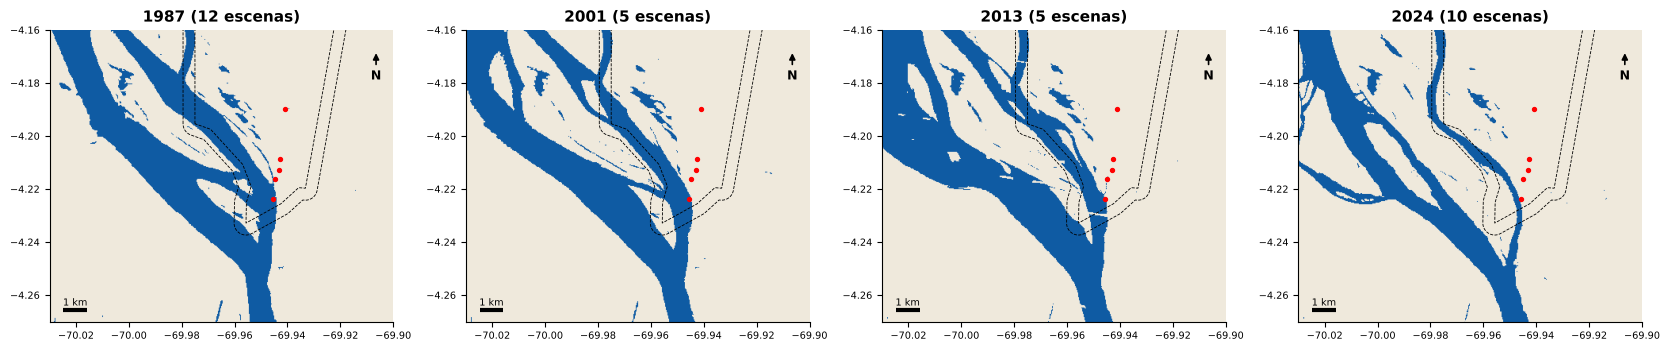

In [3]:
anios = parametros()["erosion"]["anios_comparacion"]
meses = parametros()["erosion"]["meses_aguas_bajas"]
from leticia import aoi
lugares = fuentes.lugares_clave()
urbana = aoi.area_urbana()
frente = urbana.buffer(500).difference(urbana.geometry.iloc[0]).to_crs(4326)   # franja de 500 m frente a la ciudad
fig, ax = plt.subplots(1, len(anios), figsize=(4.2 * len(anios), 4.4))
filas = []
for a, anio in zip(ax, anios):
    ds = espacial.compuesto_landsat(anio, meses, ventana_anios=1 if anio < 2000 else 0)
    agua = espacial.mndwi(ds) > parametros()["erosion"]["umbral_mndwi"]
    a.imshow(np.where(agua.values, 1.0, np.nan), extent=(float(ds.x.min()), float(ds.x.max()), float(ds.y.min()), float(ds.y.max())),
             cmap="Blues", vmin=0, vmax=1.2, zorder=1)
    a.set_facecolor("#efe9dc")
    lugares.to_crs(4326).plot(ax=a, color="red", markersize=8, zorder=3)
    frente.boundary.plot(ax=a, color="k", lw=0.6, ls="--", zorder=2)
    viz.marco(a, "bbox_rio", f"{anio} ({ds.attrs['escenas']} escenas)")
    en_frente = agua.astype(float).rio.write_crs(4326).rio.clip(frente.geometry, drop=True)
    pix_ha = (0.0003 * 111320) ** 2 * np.cos(np.radians(4.2)) / 1e4
    filas.append({"año": anio, "agua en la franja de 500 m frente a la ciudad (ha)": float(np.nansum(en_frente.values) * pix_ha)})
fig.tight_layout()
tab = pd.DataFrame(filas).set_index("año")
tab["cambio frente a 1987 (%)"] = 100 * (tab.iloc[:, 0] / tab.iloc[0, 0] - 1)
display(tab.round(0))

In [4]:
viz.pie(viz.nota_fuente("landsat") + " Agua: MNDWI > 0 en la mediana de agosto–noviembre (Xu, 2006).")

Fuente: USGS / NASA (Microsoft Planetary Computer) — Landsat Collection 2 Level-2 (reflectancia y temperatura de superficie). Agua: MNDWI > 0 en la mediana de agosto–noviembre (Xu, 2006).

**Lectura.** La franja punteada marca los 500 m de río y orilla frente a la ciudad. La sedimentación frente a
Leticia —el crecimiento de la isla de Santa Rosa y de los bancos de arena del brazo colombiano— reduce el agua
disponible junto a la ciudad en aguas bajas y aleja el canal navegable del muelle. La sequía y la dinámica
fluvial se **suman**: con el mismo nivel en la regla, hoy el agua profunda queda más lejos que hace 30 años. La
dinámica del cauce se analiza en detalle en [3.3](../33_erosion/index.md).

## 2. Días de interrupción por año

In [5]:
dias = pd.DataFrame({"< 6 m (navegación restringida)": hidro.dias_bajo_umbral(nivel, ph["umbral_estiaje_cm"]),
                     "< 4 m (puerto aislado)": hidro.dias_bajo_umbral(nivel, ph["umbral_estiaje_critico_cm"])}).fillna(0)
decadas = dias.groupby((dias.index // 10) * 10).mean().round(1)
decadas.index = [f"{d}s" for d in decadas.index]
display(Markdown("**Promedio de días por año bajo cada umbral, por década:**"))
display(decadas)

Promedio de días por año bajo cada umbral, por década:

,< 6 m (navegación restringida),< 4 m (puerto aislado)
1990s,16.50,0.00
2010s,28.30,0.00
2020s,86.00,52.00


## 3. Matriz de riesgo sistémico

In [6]:
ultimo = dias.loc[2024] if 2024 in dias.index else dias.iloc[-1]
sistemas = pd.DataFrame([
    {"sistema": "Transporte fluvial de carga (alimentos, combustible)", "umbral": "< 6 m", "días 2024": ultimo.iloc[0],
     "personas que dependen": poblacion, "consecuencia": "encarecimiento y escasez; aislamiento de comunidades ribereñas"},
    {"sistema": "Agua potable (captación en la quebrada Yahuarcaca)", "umbral": "lagos desconectados del río", "días 2024": ultimo.iloc[1],
     "personas que dependen": 0.5 * poblacion, "consecuencia": "cierre de la bocatoma; racionamiento (el resto usa pozos)"},
    {"sistema": "Pesca y seguridad alimentaria", "umbral": "lagos y várzeas secos", "días 2024": ultimo.iloc[0],
     "personas que dependen": np.nan, "consecuencia": "mortandad de peces, pérdida de ingresos"},
    {"sistema": "Salud (calidad del agua, enfermedades)", "umbral": "aguas bajas + calor", "días 2024": ultimo.iloc[0],
     "personas que dependen": poblacion, "consecuencia": "enfermedades hídricas; humo de incendios"},
    {"sistema": "Movilidad escolar y acceso a servicios", "umbral": "< 6 m", "días 2024": ultimo.iloc[0],
     "personas que dependen": np.nan, "consecuencia": "comunidades indígenas sin transporte a escuelas y centros de salud"},
]).set_index("sistema")
display(sistemas)

,umbral,días 2024,personas que dependen,consecuencia
sistema,,,,
"Transporte fluvial de carga (alimentos, combustible)",< 6 m,86,"46,507.02",encarecimiento y escasez; aislamiento de comun...
Agua potable (captación en la quebrada Yahuarcaca),lagos desconectados del río,52,"23,253.51",cierre de la bocatoma; racionamiento (el resto...
Pesca y seguridad alimentaria,lagos y várzeas secos,86,NaN,"mortandad de peces, pérdida de ingresos"
"Salud (calidad del agua, enfermedades)",aguas bajas + calor,86,"46,507.02",enfermedades hídricas; humo de incendios
Movilidad escolar y acceso a servicios,< 6 m,86,NaN,comunidades indígenas sin transporte a escuela...


La tabla resume la cadena de impactos documentada en las vaciantes recientes: carga sin poder atracar, alza de
precios y comunidades aisladas en 2023–2024 [@ideam2024comunicado100; @costa2023spa], y el cierre de la bocatoma del
acueducto cuando la quebrada Yahuarcaca pierde caudal, como ocurrió en enero de 2022 por la barra de arena que
seca su canal; según la Universidad Nacional, cerca de la mitad de la población depende de esa captación y el resto
se abastece de pozos [@bluradio2022agua]. Toda la población de la cabecera estimada en
[2.6](../../02_datos/26_area_estudio.ipynb) depende del transporte fluvial.

Estudios recientes en Brasil documentan la misma cadena. La sequía de 2023 en la Amazonía central dejó como principal
impacto socioeconómico la navegación interrumpida, con efectos sobre la pesca, la producción de harina de yuca y el
acceso a la salud, al agua potable y a los mercados urbanos; la población urbana resistió mejor que la rural
[@fleischmann2025]. En las sequías de 2000–2020, la mayoría de las noticias recopiladas por Santos de Lima et al.
reportaban barreras a la navegación que aislaban comunidades y limitaban su acceso a alimentos, combustible,
medicinas, salud y educación [@santosdelima2024]. Para Leticia, la duración de las aguas bajas calculada en
[3.2.b](b_amenaza.ipynb) es el indicador que mejor resume la exposición a esa cadena.

## 4. Probabilidad de un año como 2024

In [7]:
minimos = hidro.extremos_anuales(nivel, "min")["valor"]
p_par = hidro.ajustar_gev(minimos.values, minimos=True)
from scipy import stats
for u in (ph["umbral_estiaje_cm"], ph["umbral_estiaje_critico_cm"], 300):
    p = stats.genextreme.sf(-u, *p_par)
    display(Markdown(f"- Probabilidad anual de que el mínimo baje de **{u/100:.0f} m**: {100*p:.0f} % (una vez cada {1/p:.0f} años)."))

Probabilidad anual de que el mínimo baje de 6 m : 34 % (una vez cada 3 años).

Probabilidad anual de que el mínimo baje de 4 m : 9 % (una vez cada 11 años).

Probabilidad anual de que el mínimo baje de 3 m : 2 % (una vez cada 44 años).

## 5. Comunidades ribereñas: distancia al río en aguas bajas

Santos de Lima et al. identificaron los asentamientos expuestos al aislamiento midiendo la distancia en línea recta
de cada uno al cuerpo de agua navegable más cercano en aguas altas y en aguas bajas: en la Amazonía brasileña, la
proporción de localidades a menos de 1 km del agua bajó de 77 % a 74 % entre una temporada y otra
[@santosdelima2024]. Aquí se replica para el corredor del Amazonas en el municipio. Como no hay una capa pública de
comunidades, los asentamientos son los hexágonos de población de Kontur fuera del casco urbano; el agua navegable
es el **cauce principal conectado** (el río y lo que se comunica con él) en tres momentos: aguas altas y aguas bajas
típicas según el JRC Global Surface Water [@pekel2016], y el fondo de la vaciante de 2024 según Landsat.

In [8]:
from leticia import exposicion
pa = ph["aislamiento"]
asent = exposicion.asentamientos_rurales("bbox_ribera", pa["poblacion_minima"])
occ = fuentes.raster_estatico("jrc-gsw", "occurrence", clave_bbox="bbox_ribera")
estac = fuentes.raster_estatico("jrc-gsw", "seasonality", clave_bbox="bbox_ribera")
ds = espacial.compuesto_landsat(pa["anio_vaciante"], pa["meses_vaciante"], clave_bbox="bbox_ribera")
vaciante = f"vaciante de {pa['anio_vaciante']}"
mascaras = {"aguas altas": (estac >= 1) & (estac <= 12),
            "aguas bajas típicas": (occ >= pa["ocurrencia_permanente"]) & (occ <= 100),
            vaciante: espacial.mndwi(ds) > parametros()["erosion"]["umbral_mndwi"]}
for nombre, m in mascaras.items():
    asent[nombre] = espacial.distancia_a_cauce(m, asent) / 1000
km1, km5 = pa["distancias_km"]
ribera = asent[asent["aguas altas"] < 2]          # asentamientos que viven del río (a menos de 2 km en aguas altas)
def resumen(g):
    w = g["poblacion"]
    return pd.DataFrame({k: {"distancia media (km)": np.average(g[k], weights=w),
                             f"población a menos de {km1} km (%)": 100 * w[g[k] < km1].sum() / w.sum(),
                             f"población a más de {km5} km (%)": 100 * w[g[k] > km5].sum() / w.sum()} for k in mascaras}).T
miles = lambda v: f"{v:,.0f}".replace(",", ".")
display(Markdown(f"**Todos los asentamientos fuera del casco urbano** ({len(asent)} hexágonos; {miles(asent['poblacion'].sum())} personas):"))
display(resumen(asent).round(1))
display(Markdown(f"**Asentamientos ribereños**, a menos de 2 km del río en aguas altas ({len(ribera)} hexágonos; {miles(ribera['poblacion'].sum())} personas):"))
display(resumen(ribera).round(1))

Todos los asentamientos fuera del casco urbano (79 hexágonos; 5.147 personas):

,distancia media (km),población a menos de 1 km (%),población a más de 5 km (%)
aguas altas,2.60,44.60,20.50
aguas bajas típicas,2.70,41.80,21.00
vaciante de 2024,2.80,33.20,20.50


Asentamientos ribereños , a menos de 2 km del río en aguas altas (41 hexágonos; 2.717 personas):

,distancia media (km),población a menos de 1 km (%),población a más de 5 km (%)
aguas altas,0.60,84.50,0.00
aguas bajas típicas,0.70,79.20,0.00
vaciante de 2024,0.90,62.90,0.00


Asentamientos que quedaron más de 1 km más lejos del cauce conectado en la vaciante de 2024 que en aguas altas (círculos negros): 3 , con 340 personas.

,nombre,personas,aguas altas,aguas bajas típicas,vaciante de 2024,alejamiento (km)
48,La Palmera,25.00,0.28,0.30,2.72,2.44
49,La Palmera,167.00,0.56,0.59,2.47,1.92
50,La Palmera,148.00,0.00,0.00,1.82,1.82


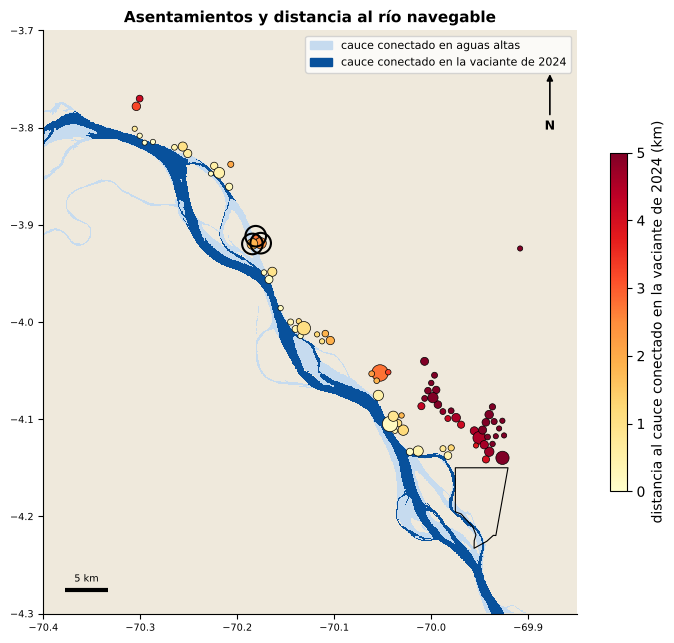

In [9]:
asent["alejamiento_km"] = asent[vaciante] - asent["aguas altas"]
alejados = asent[asent["alejamiento_km"] > 1].sort_values("alejamiento_km", ascending=False)
nombres = intentar(fuentes.nombres_lugares, alejados, mensaje="Nominatim no respondió")
if nombres is not None:
    alejados = alejados.assign(nombre=nombres.replace("", "sin nombre en OpenStreetMap"))
fig, ax = plt.subplots(figsize=(8.6, 8))
ax.set_facecolor("#efe9dc")
colores = {"aguas altas": "#c6dbef", vaciante: "#08519c"}
for nombre, color in colores.items():
    c_ = espacial.cauce_principal(mascaras[nombre])
    ax.imshow(np.where(c_.values, 1.0, np.nan), extent=(float(c_.x.min()), float(c_.x.max()), float(c_.y.min()), float(c_.y.max())),
              cmap=matplotlib.colors.ListedColormap([color]), zorder=1 if nombre == "aguas altas" else 2, interpolation="nearest")
g = asent.to_crs(4326)
sc = ax.scatter(g.geometry.x, g.geometry.y, c=asent[vaciante], cmap="YlOrRd", vmin=0, vmax=5, s=10 + asent["poblacion"] / 3,
                edgecolor="k", lw=0.5, zorder=4)
a_ = alejados.to_crs(4326)
ax.scatter(a_.geometry.x, a_.geometry.y, s=220, facecolor="none", edgecolor="k", lw=1.5, zorder=5)
aoi.area_urbana().to_crs(4326).boundary.plot(ax=ax, color="k", lw=0.8, zorder=3)
fig.colorbar(sc, ax=ax, shrink=0.55, label=f"distancia al cauce conectado en la {vaciante} (km)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=colores["aguas altas"], label="cauce conectado en aguas altas"),
                   Patch(color=colores[vaciante], label=f"cauce conectado en la {vaciante}")], loc="upper right", fontsize=8, frameon=True)
viz.marco(ax, "bbox_ribera", "Asentamientos y distancia al río navegable")
cols = [c for c in ("nombre", "poblacion", "aguas altas", "aguas bajas típicas", vaciante, "alejamiento_km") if c in alejados]
display(Markdown(f"Asentamientos que quedaron **más de 1 km más lejos** del cauce conectado en la {vaciante} que en aguas altas "
                 f"(círculos negros): **{len(alejados)}**, con {miles(alejados['poblacion'].sum())} personas."))
display(alejados[cols].rename(columns={"poblacion": "personas", "alejamiento_km": "alejamiento (km)"}).round(2))

In [10]:
viz.pie(viz.nota_fuente("poblacion", "agua_superficial_jrc", "landsat") + " Distancia en línea recta al cuerpo de agua conectado más grande; "
        "nombres de OpenStreetMap (Nominatim).")

Fuente: Kontur (GHSL, Facebook HRSL, Microsoft Buildings, Copernicus) — Kontur Population Colombia 2023-11-01; JRC – Global Surface Water (Pekel et al. 2016) — occurrence, seasonality, transitions, extent; USGS / NASA (Microsoft Planetary Computer) — Landsat Collection 2 Level-2 (reflectancia y temperatura de superficie). Distancia en línea recta al cuerpo de agua conectado más grande; nombres de OpenStreetMap (Nominatim).

**Lectura.** Entre los habitantes ribereños, la proporción que vive a menos de 1 km del río navegable pasa de
**85 %** en aguas altas a 79 % en aguas bajas típicas y a **63 %** en la vaciante de 2024. Es una caída mayor que la
que Santos de Lima et al. encontraron en Brasil entre temporadas (de 77 % a 74 % de las localidades), aunque aquí se
cuenta población y no localidades. Frente a La Palmera los brazos del río se desconectaron y el cauce navegable
quedó a 2–3 km. Es el patrón que, según ese estudio, obliga a caminar por playas y barro para llegar al agua
navegable, con efectos sobre el abastecimiento, la salud y la educación. Los asentamientos a más de 5 km, sobre la vía a Tarapacá, dependen de la
carretera y no del río. La distancia en línea recta no mide la profundidad del canal: un brazo conectado puede no
ser navegable para las embarcaciones de carga.

:::{important} Riesgo sistémico, respuesta sistémica
Las medidas que reducen este riesgo no son obras en un barrio sino **capacidades de la ciudad**: reservas
estratégicas de alimentos y combustible antes de la vaciante, fuentes alternas de agua (pozos, captación de
lluvia), monitoreo del canal navegable con la Armada y la Capitanía de Puerto, y un protocolo de alerta que use
los pronósticos de GloFAS y del IDEAM. El PIGCCT de Amazonas ya identifica el desabastecimiento hídrico como
amenaza priorizada [@pigcct2022amazonas].
:::